In [19]:
from matplotlib import pyplot as plt
import numpy as np
from scipy.special import jv, kv
from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
import math

In [2]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [3]:
import sys
from pathlib import Path
import joblib
import time

src_path = Path("/Users/tliu/oh_suppression/codes/src")

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from oh_suppression.coupling import *

In [4]:
from oh_suppression.point_source_coupling import *
from oh_suppression.flat_background_coupling import *
from oh_suppression.extended_source_coupling import *

In [5]:
from oh_suppression.point_source_coupling import *
from oh_suppression.image_plane_fields import *

In [6]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import special #import jv, kv
# from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0
from scipy.optimize import brentq
from scipy.optimize import fminbound
from dataclasses import dataclass
import pandas as pd
from joblib import Parallel, delayed
import os

In [7]:
import astropy.units as u

from astropy.modeling.models import Sersic2D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Sersic2D.html

In [8]:
r_max = 125e-6
n_grid = 1000

x_1d = np.linspace(-r_max, r_max, n_grid)
y_1d = np.linspace(-r_max, r_max, n_grid)

x, y = np.meshgrid(x_1d, y_1d)

In [9]:
prepared_modes_25microns = prepare_modes_2d(x, y, a=25e-6, NA=0.1, lam0=1.5e-6, az_sym=False, mode_case="few_mode")

In [10]:
def extract_mode_field(prepared_modes, l, m, angular=None):
    """
    Extract the electric-field and intensity arrays for one LP mode.

    Parameters
    ----------
    prepared_modes : list
        Output from prepare_modes_2d().

    l : int
        Azimuthal mode number.

    m : int
        Radial mode number.

    angular : str or None
        "cos" or "sin".

        For l = 0, angular can be left as None because only one
        angular component exists.

        For l != 0, specify "cos" or "sin".

    Returns
    -------
    E_mode : 2D numpy.ndarray
        Electric-field amplitude.

    I_mode : 2D numpy.ndarray
        Mode intensity |E_mode|^2.
    """

    matching_modes = [
        mode for mode in prepared_modes
        if mode["l"] == l and mode["m"] == m
    ]

    if angular is not None:
        matching_modes = [
            mode for mode in matching_modes
            if mode["angular"] == angular
        ]

    if len(matching_modes) == 0:
        raise ValueError(
            f"LP{l}{m}"
            + (f" {angular}" if angular is not None else "")
            + " was not found."
        )

    # l != 0 has both cos and sin components,
    # so require the user to choose one.
    if len(matching_modes) > 1:
        raise ValueError(
            f"LP{l}{m} has multiple angular components. "
            "Specify angular='cos' or angular='sin'."
        )

    mode = matching_modes[0]

    return mode["E_mode"], mode["I_mode"]

In [11]:
# # Extract sin and cosine components of LP11
# lp11_sin = prepared_modes_25microns

In [12]:
E_LP11_cos, I_LP11_cos = extract_mode_field(
    prepared_modes_25microns,
    l=1,
    m=1,
    angular="cos"
)

E_LP11_sin, I_LP11_sin = extract_mode_field(
    prepared_modes_25microns,
    l=1,
    m=1,
    angular="sin"
)

E_LP21_cos, I_LP21_cos = extract_mode_field(
    prepared_modes_25microns,
    l=2,
    m=1,
    angular="cos"
)

E_LP21_sin, I_LP21_sin = extract_mode_field(
    prepared_modes_25microns,
    l=2,
    m=1,
    angular="sin"
)

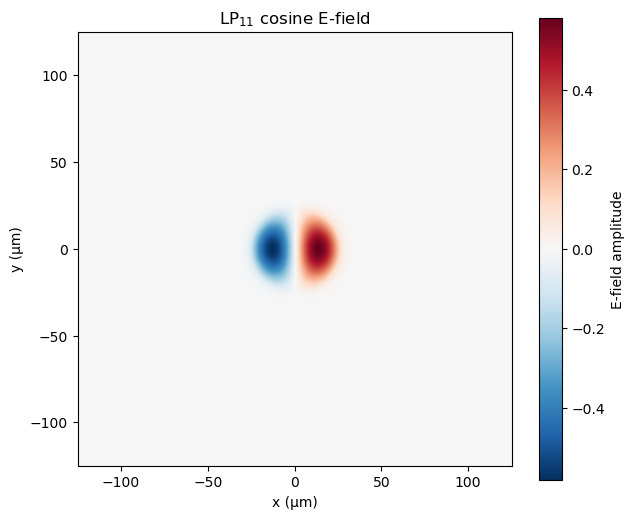

In [13]:
plt.figure(figsize=(7, 6))

# Use blue to represent negative values and red to represent positive values
plt.imshow(
    E_LP11_cos,
    extent=[
        x_1d.min() * 1e6,
        x_1d.max() * 1e6,
        y_1d.min() * 1e6,
        y_1d.max() * 1e6
    ],
    origin="lower",
    aspect="equal",
    cmap="RdBu_r"
)

plt.colorbar(label="E-field amplitude")

plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.title(r"LP$_{11}$ cosine E-field")

plt.show()

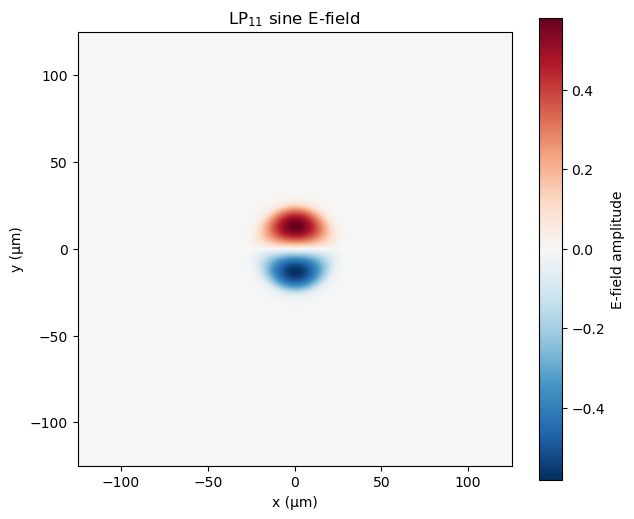

In [14]:
plt.figure(figsize=(7, 6))

plt.imshow(
    E_LP11_sin,
    extent=[
        x_1d.min() * 1e6,
        x_1d.max() * 1e6,
        y_1d.min() * 1e6,
        y_1d.max() * 1e6
    ],
    origin="lower",
    aspect="equal", 
    cmap="RdBu_r"
)

plt.colorbar(label="E-field amplitude")

plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.title(r"LP$_{11}$ sine E-field")

plt.show()

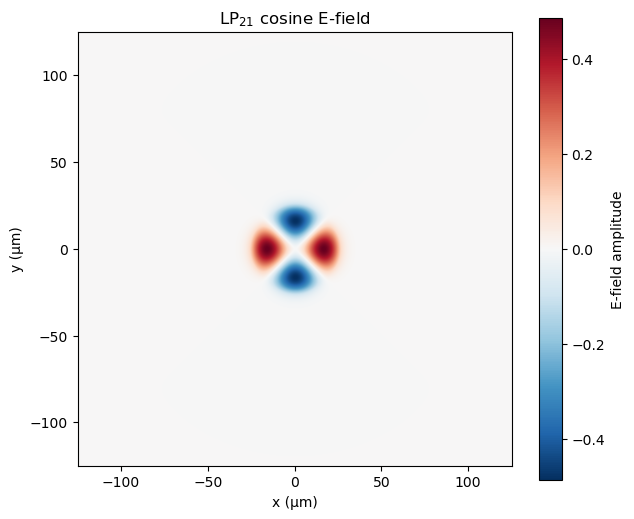

In [15]:
plt.figure(figsize=(7, 6))

plt.imshow(
    E_LP21_cos,
    extent=[
        x_1d.min() * 1e6,
        x_1d.max() * 1e6,
        y_1d.min() * 1e6,
        y_1d.max() * 1e6
    ],
    origin="lower",
    aspect="equal", 
    cmap="RdBu_r"
)

plt.colorbar(label="E-field amplitude")

plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.title(r"LP$_{21}$ cosine E-field")

plt.show()

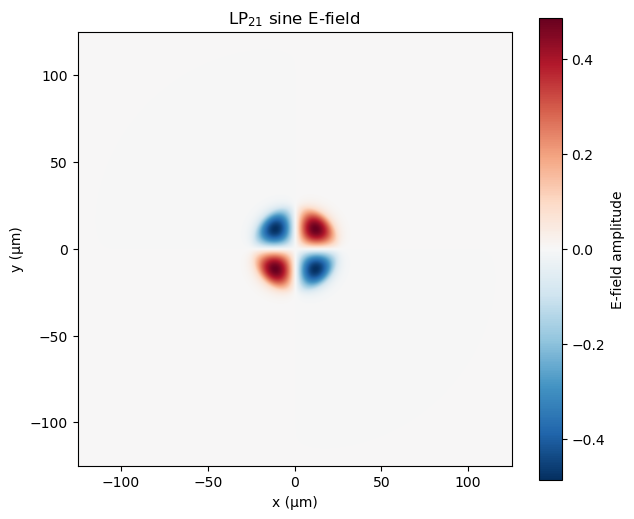

In [16]:
plt.figure(figsize=(7, 6))

plt.imshow(
    E_LP21_sin,
    extent=[
        x_1d.min() * 1e6,
        x_1d.max() * 1e6,
        y_1d.min() * 1e6,
        y_1d.max() * 1e6
    ],
    origin="lower",
    aspect="equal", 
    cmap="RdBu_r"
)

plt.colorbar(label="E-field amplitude")

plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.title(r"LP$_{21}$ sine E-field")

plt.show()

In [17]:
decentre_array = np.linspace(0, 25e-6, 200)

In [18]:
1/8

0.125

In [ ]:
tot_eta_psf_25micron_centred, mode_eta_25micron_centred = eta_psf_vs_radial_decentre_position(
    prepared_modes_25microns, 
    x, y, x_1d, y_1d,
    lam0=1.5e-6, F_eff=5, alpha = 0.125, 
    decentre_array=decentre_array)

In [ ]:
def extract_mode_eta(mode_results_all, l, m, angular=None):
    """
    Extract coupling efficiency as a function of decentre position
    for one LP mode from mode_results_all.

    Parameters
    ----------
    mode_results_all : list
        Output returned by eta_psf_vs_radial_decentre_position().
        Each element corresponds to one decentre position and contains
        a list of dictionaries for the supported fibre modes.

    l : int
        Azimuthal order of the LP mode.

    m : int
        Radial order of the LP mode.

    angular : str or None
        "cos" or "sin" to extract one angular component.
        If None, sum all angular components belonging to the same
        (l, m) mode family.

    Returns
    -------
    eta_array : numpy.ndarray
        Coupling efficiency for the selected mode at each
        decentre position.
    """

    eta_array = []

    for mode_results in mode_results_all:

        matching_modes = [
            mode for mode in mode_results
            if mode["l"] == l and mode["m"] == m
        ]

        if angular is not None:
            matching_modes = [
                mode for mode in matching_modes
                if mode["angular"] == angular
            ]

        if len(matching_modes) == 0:
            raise ValueError(
                f"LP{l}{m}"
                + (f" {angular}" if angular is not None else "")
                + " was not found."
            )

        # Sum cos + sin if angular=None.
        eta = sum(mode["eta"] for mode in matching_modes)

        eta_array.append(eta)

    return np.array(eta_array)

In [ ]:
eta_LP11 = extract_mode_eta(
    mode_eta_25micron_centred,
    l=1,
    m=1
)

eta_LP21 = extract_mode_eta(
    mode_eta_25micron_centred,
    l=2,
    m=1
)

In [ ]:
eta_LP11

array([1.48137882e-16, 2.61698683e-05, 1.04661254e-04, 2.35418973e-04,
       4.18351069e-04, 6.53328833e-04, 9.40186837e-04, 1.27872297e-03,
       1.66869851e-03, 2.10983814e-03, 2.60183006e-03, 3.14432606e-03,
       3.73694157e-03, 4.37925582e-03, 5.07081190e-03, 5.81111690e-03,
       6.59964206e-03, 7.43582288e-03, 8.31905928e-03, 9.24871579e-03,
       1.02241217e-02, 1.12445713e-02, 1.23093240e-02, 1.34176047e-02,
       1.45686038e-02, 1.57614776e-02, 1.69953486e-02, 1.82693057e-02,
       1.95824044e-02, 2.09336673e-02, 2.23220845e-02, 2.37466135e-02,
       2.52061800e-02, 2.66996783e-02, 2.82259713e-02, 2.97838915e-02,
       3.13722407e-02, 3.29897914e-02, 3.46352864e-02, 3.63074401e-02,
       3.80049384e-02, 3.97264397e-02, 4.14705754e-02, 4.32359505e-02,
       4.50211440e-02, 4.68247104e-02, 4.86451794e-02, 5.04810574e-02,
       5.23308280e-02, 5.41929529e-02, 5.60658729e-02, 5.79480085e-02,
       5.98377610e-02, 6.17335136e-02, 6.36336325e-02, 6.55364676e-02,
      

In [ ]:
# # Plot the electric field of all modes with negative and positive values represented by blue and red colors, respectively. For asymmetric modes, plot the cosine and sine components separately. Use a colorbar to indicate the amplitude of the electric field.

# def plot_mode_fields(prepared_modes, angular="cosine"): 
#     """
#     """

#     for mode in prepared_modes:
#         l = mode["l"]
#         m = mode["m"]
#         if angular is "cosine":
#             angular = mode["angular"][0]
#         elif angular is "sine":
#             angular = mode["angular"][1]

#         E_mode, I_mode = extract_mode_field(prepared_modes, l, m, angular)

#         # Create a subfigure for each mode, the number of subfigures is in the matrix size of l as rows and m as columns, for cosine or sine components. 
#         # Figure size depends on the number of modes. 
#         plt.figure()

#         plt.ax1 = plt.subplot

#         plt.imshow(
#             E_mode,
#             extent=[
#                 x_1d.min() * 1e6,
#                 x_1d.max() * 1e6,
#                 y_1d.min() * 1e6,
#                 y_1d.max() * 1e6
#             ],
#             origin="lower",
#             aspect="equal",
#             cmap="RdBu_r"
#         )

#         plt.colorbar(label="E-field amplitude")

#         plt.xlabel("x (µm)")
#         plt.ylabel("y (µm)")
#         title_str = f"LP$_{{{l}{m}}}$"
#         if angular is not None:
#             title_str += f" {angular}"
#         title_str += " E-field"
#         plt.title(title_str)

#         plt.show()


In [25]:
def plot_mode_fields_by_lm(
        prepared_modes,
        x_1d,
        y_1d,
        angular="all"
):
    """
    Plot fibre-mode electric fields.

    Columns correspond to radial order m.

    Parameters
    ----------
    prepared_modes : list of dict
        Output from prepare_modes_2d().

    x_1d, y_1d : 1D arrays
        Coordinate axes [m].

    angular : str
        "cos" -> cosine components only
                 (also includes l=0 symmetric modes)
        "sin" -> sine components only
                 (l=0 modes are excluded)
        "all" -> cosine and sine components,
                 with separate rows for l > 0
    """

    if angular not in ["all", "cos", "sin"]:
        raise ValueError(
            "angular must be 'all', 'cos', or 'sin'"
        )

    l_values = sorted(
        set(mode["l"] for mode in prepared_modes)
    )

    m_max = max(
        mode["m"] for mode in prepared_modes
    )

    # --------------------------------------------------
    # Decide which rows to create
    # --------------------------------------------------
    row_labels = []

    for l in l_values:

        if l == 0:

            # l=0 has no separate sine component
            if angular in ["all", "cos"]:
                row_labels.append((l, "cos"))

        else:

            if angular == "all":
                row_labels.append((l, "cos"))
                row_labels.append((l, "sin"))

            elif angular == "cos":
                row_labels.append((l, "cos"))

            elif angular == "sin":
                row_labels.append((l, "sin"))

    nrows = len(row_labels)
    ncols = m_max

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(4.2 * ncols, 4.0 * nrows),
        squeeze=False
    )

    extent = [
        x_1d.min() * 1e6,
        x_1d.max() * 1e6,
        y_1d.min() * 1e6,
        y_1d.max() * 1e6
    ]

    # --------------------------------------------------
    # Fill subplot grid
    # --------------------------------------------------
    for i, (l, angular_component) in enumerate(row_labels):

        for m in range(1, m_max + 1):

            ax = axes[i, m - 1]

            matching_modes = [
                mode
                for mode in prepared_modes
                if (
                    mode["l"] == l
                    and mode["m"] == m
                    and mode["angular"] == angular_component
                )
            ]

            # Unsupported (l,m)
            if len(matching_modes) == 0:
                ax.axis("off")
                continue

            mode = matching_modes[0]

            E_mode = mode["E_mode"]

            # Symmetric colour limits around E = 0
            Emax = np.max(np.abs(E_mode))

            im = ax.imshow(
                E_mode,
                extent=extent,
                origin="lower",
                aspect="equal",
                cmap="RdBu_r",
                vmin=-Emax,
                vmax=Emax
            )

            # ------------------------------------------
            # Labels
            # ------------------------------------------
            ax.set_xlabel("x (µm)")
            ax.set_ylabel("y (µm)")

            if l == 0:
                title = rf"LP$_{{{l}{m}}}$"
            else:
                title = (
                    rf"LP$_{{{l}{m}}}$ "
                    f"{angular_component}"
                )

            ax.set_title(title)

            cbar = fig.colorbar(
                im,
                ax=ax,
                fraction=0.046,
                pad=0.04
            )

            cbar.set_label("E-field amplitude")

    plt.tight_layout()
    plt.show()

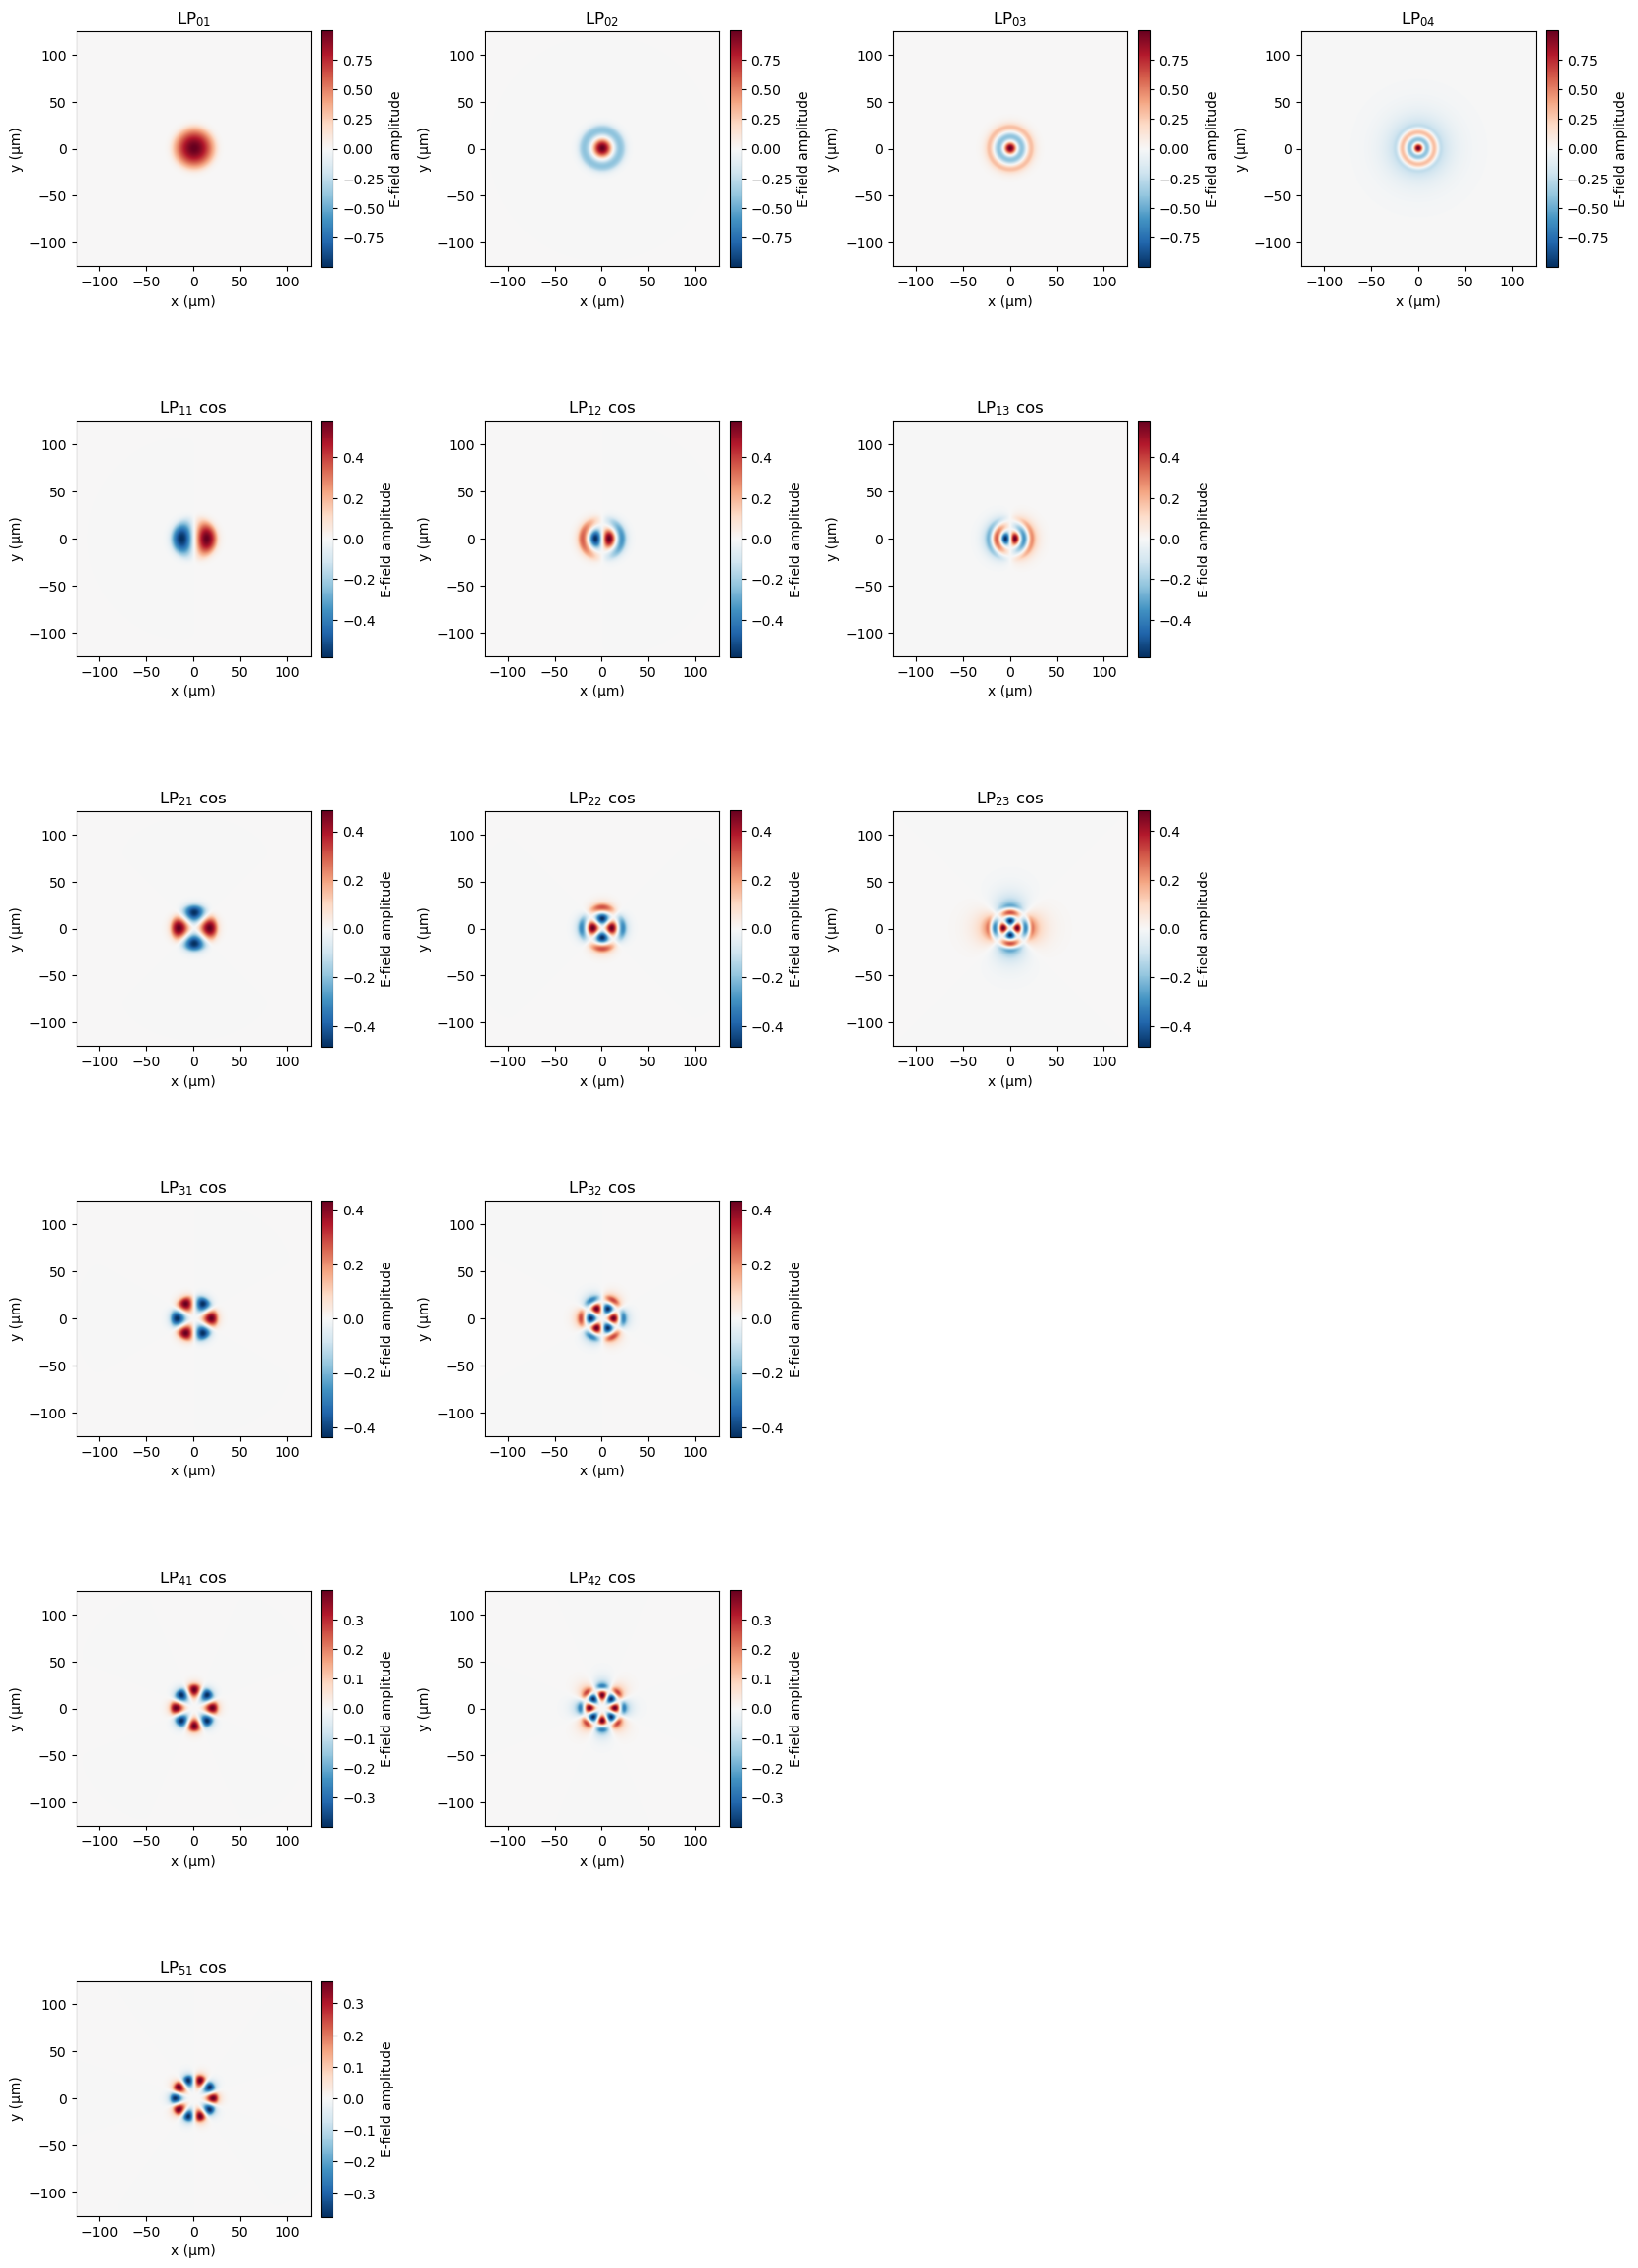

In [27]:
plot_mode_fields_by_lm(
    prepared_modes_25microns,
    x_1d,
    y_1d,
    angular="cos"
)

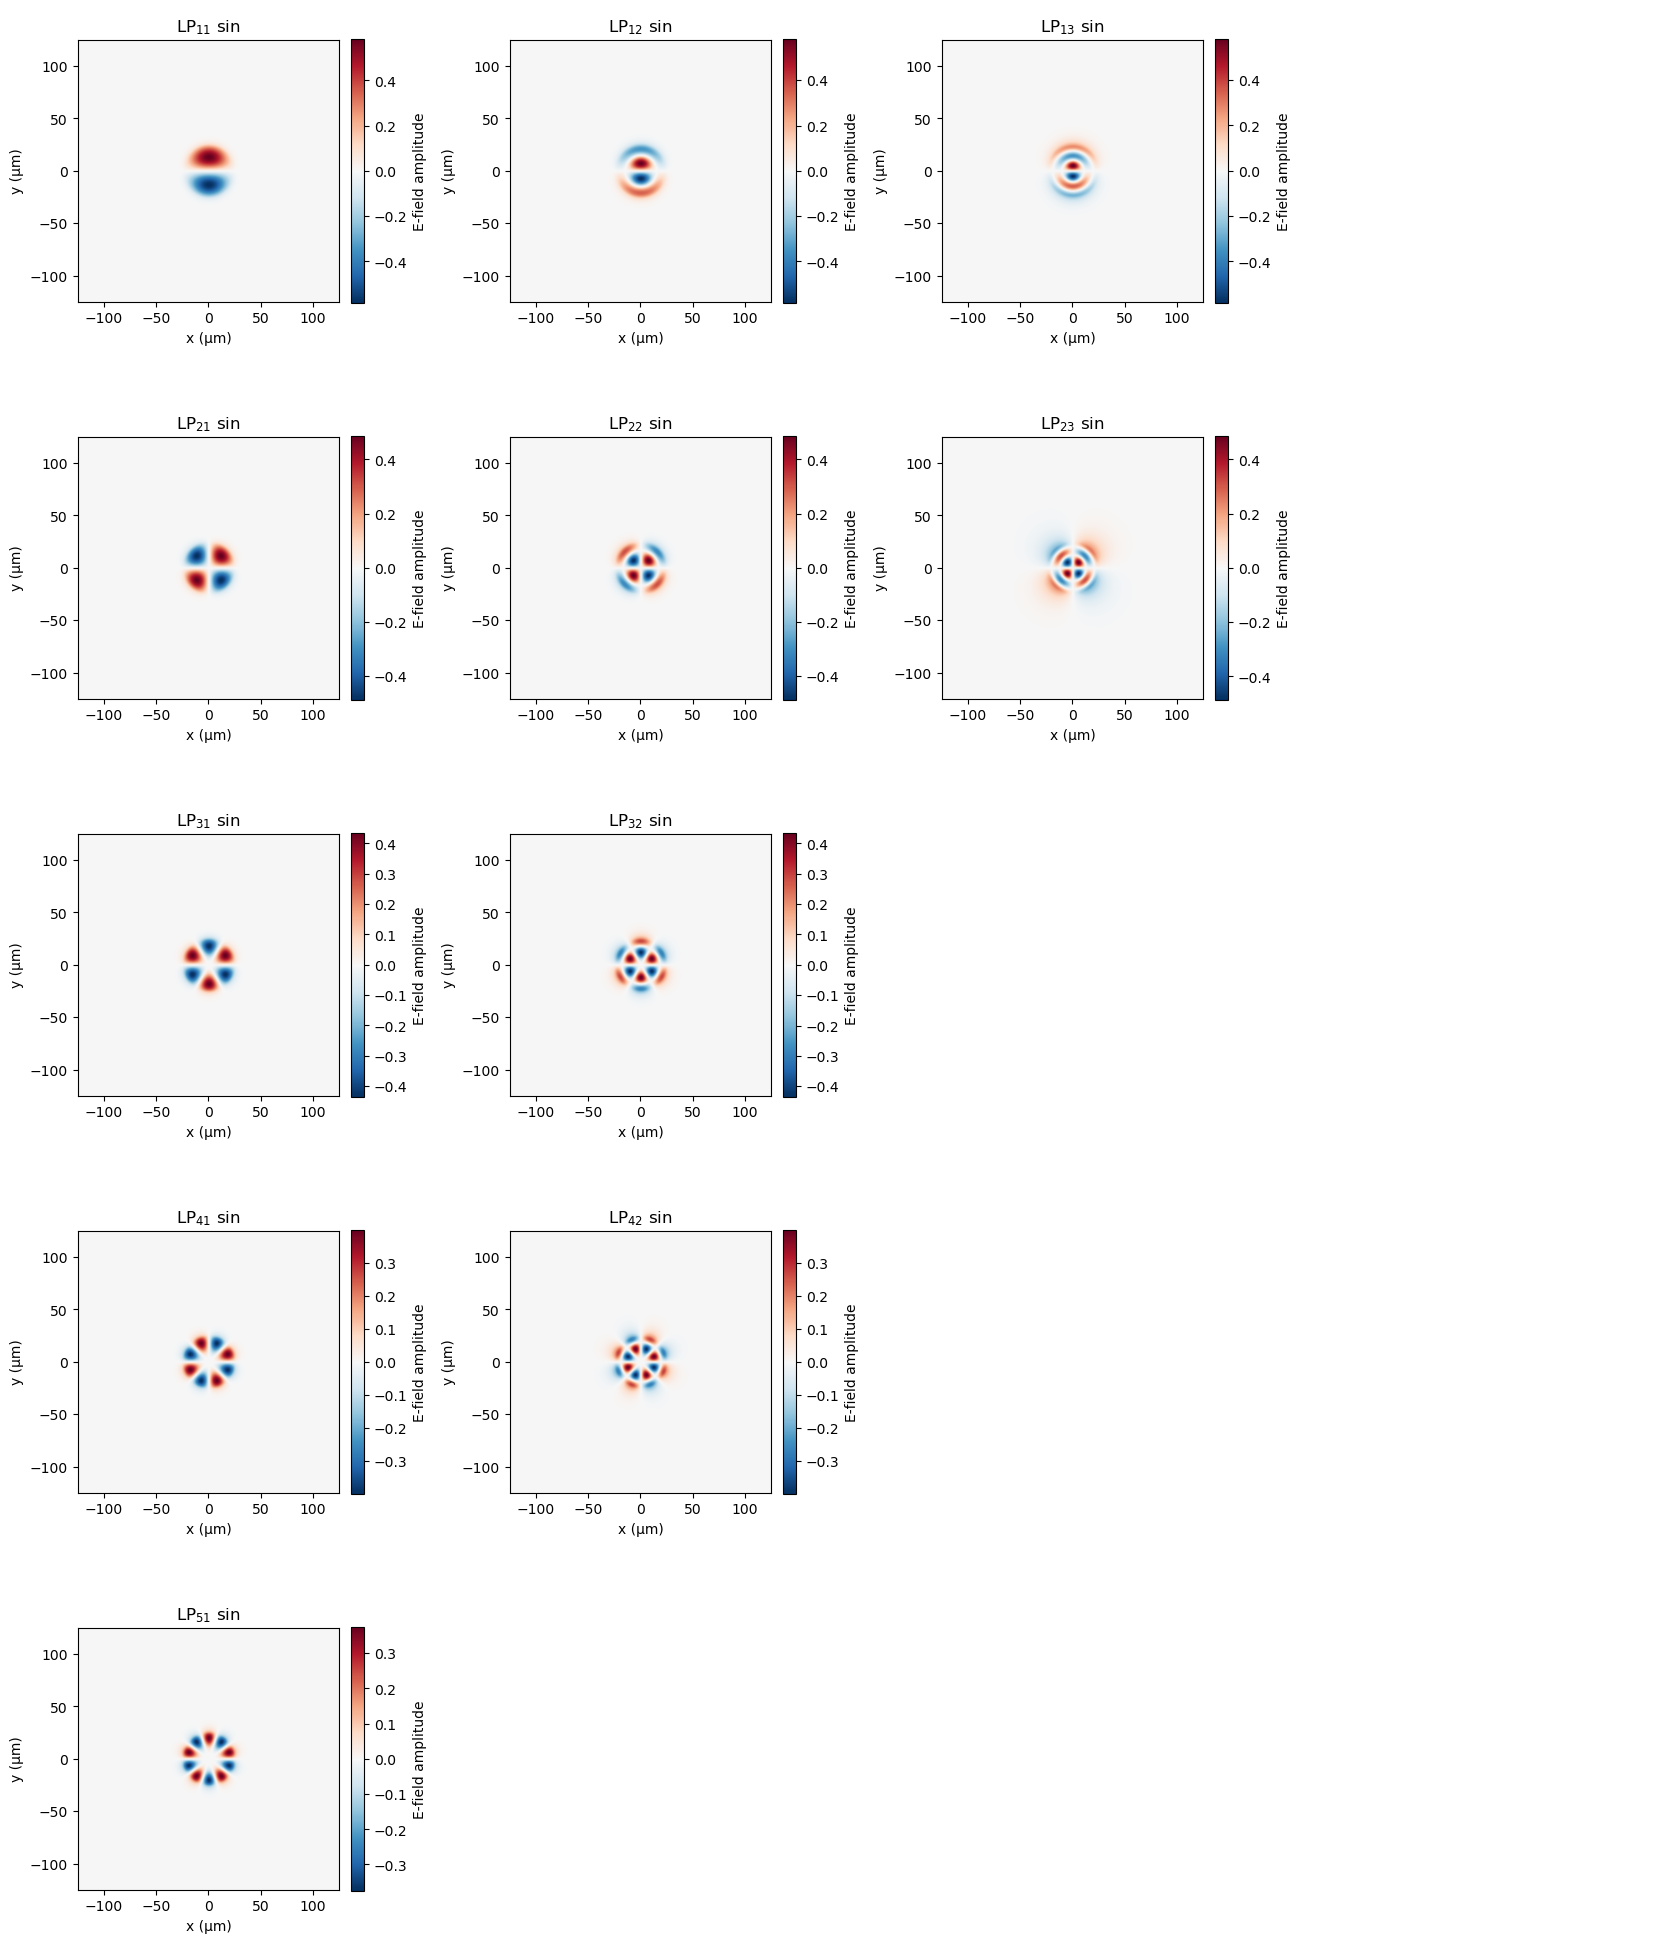

In [28]:
plot_mode_fields_by_lm(
    prepared_modes_25microns,
    x_1d,
    y_1d,
    angular="sin"
)

In [31]:
def sigma_jitter_milliarcsec_to_metres(sigma_jitter_rms, focal_length, demagnification): 
    """
    Convert the RMS jitter from milliarcseconds to metres at the fibre plane.

    Parameters: 
    sigma_jitter_rms : float
        RMS jitter in milliarcseconds.
    focal_length : float
        Focal length of the telescope in metres.
    demagnification : float 
        Demagnification factor from the telescope focal plane to the fibre plane, done by the reimaging optics. 

    Returns:
    float
        RMS jitter in metres at the fibre plane.
    """
    # Convert jitter from milliarcseconds to radians
    sigma_theta_radians = sigma_jitter_rms * 1e-3 / 206265 

    # Convert jitter from radians to physical units (metres) at the fibre plane using the focal length and demagnification

    sigma_jitter_metres = demagnification * focal_length * sigma_theta_radians

    return sigma_jitter_metres

In [43]:
focal_length = 399 # metres, the focal length of the telescope
demagnification = 5/49.9
dx_200mas = sigma_jitter_milliarcsec_to_metres(200.0, focal_length, demagnification)
dy_200mas = 0

In [39]:
demagnification

0.10020040080160321

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Extract LP01
# ============================================================

E_LP01, I_LP01 = extract_mode_field(
    prepared_modes_25microns,
    l=0,
    m=1
)

# ============================================================
# 2. Generate centred and 200 mas decentred image fields
# ============================================================

E_psf_centred, I_psf_centred = diffraction_limited_E_field_at_fibre_2d(
    x, y,
    lam0=1.5e-6,
    F_eff=5,
    alpha=0.0,
    decentre=(0.0, 0.0),
    E_S=1.0
)

E_psf_decentred, I_psf_decentred = diffraction_limited_E_field_at_fibre_2d(
    x, y,
    lam0=1.5e-6,
    F_eff=5,
    alpha=0.125,
    decentre=(dx_200mas, dy_200mas),
    E_S=1.0
)

# ============================================================
# 3. Overlap integrands
# ============================================================

overlap_centred = np.real(
    E_psf_centred * np.conjugate(E_LP01)
)

overlap_decentred = np.real(
    E_psf_decentred * np.conjugate(E_LP01)
)

# ============================================================
# 4. Common plotting quantities
# ============================================================

extent = [
    x_1d.min() * 1e6,
    x_1d.max() * 1e6,
    y_1d.min() * 1e6,
    y_1d.max() * 1e6
]

Emax_mode = np.max(np.abs(E_LP01))

# Same image-field scale for centred and decentred plots
Emax_psf = max(
    np.max(np.abs(E_psf_centred)),
    np.max(np.abs(E_psf_decentred))
)

# Same overlap scale for centred and decentred plots
Emax_overlap = max(
    np.max(np.abs(overlap_centred)),
    np.max(np.abs(overlap_decentred))
)

In [48]:
def plot_overlap_case(
        E_mode,
        E_image,
        overlap,
        title
):
    """
    Plot:
        fibre eigenmode | image electric field | overlap integrand
    """

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 4.5)
    )

    # --------------------------------------------------------
    # LP01 eigenmode
    # --------------------------------------------------------

    im0 = axes[0].imshow(
        E_mode,
        extent=extent,
        origin="lower",
        aspect="equal",
        cmap="RdBu_r",
        vmin=-Emax_mode,
        vmax=Emax_mode
    )

    axes[0].set_title(r"LP$_{01}$ eigenmode field")
    axes[0].set_xlabel("x (µm)")
    axes[0].set_ylabel("y (µm)")

    cbar0 = fig.colorbar(
        im0,
        ax=axes[0],
        fraction=0.046,
        pad=0.04
    )
    cbar0.set_label("E-field amplitude")

    # --------------------------------------------------------
    # Image electric field
    # --------------------------------------------------------

    im1 = axes[1].imshow(
        E_image,
        extent=extent,
        origin="lower",
        aspect="equal",
        cmap="RdBu_r",
        vmin=-Emax_psf,
        vmax=Emax_psf
    )

    axes[1].set_title(r"Image $E$-field")
    axes[1].set_xlabel("x (µm)")
    axes[1].set_ylabel("y (µm)")

    cbar1 = fig.colorbar(
        im1,
        ax=axes[1],
        fraction=0.046,
        pad=0.04
    )
    cbar1.set_label("E-field amplitude")

    # --------------------------------------------------------
    # Point-by-point overlap
    # --------------------------------------------------------

    im2 = axes[2].imshow(
        overlap,
        extent=extent,
        origin="lower",
        aspect="equal",
        cmap="RdBu_r",
        vmin=-Emax_overlap,
        vmax=Emax_overlap
    )

    axes[2].set_title(
        r"$E_{\rm image}E_{\rm LP01}^{*}$"
    )
    axes[2].set_xlabel("x (µm)")
    axes[2].set_ylabel("y (µm)")

    cbar2 = fig.colorbar(
        im2,
        ax=axes[2],
        fraction=0.046,
        pad=0.04
    )
    cbar2.set_label("Overlap-integrand amplitude")

    fig.suptitle(
        title,
        fontsize=15,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

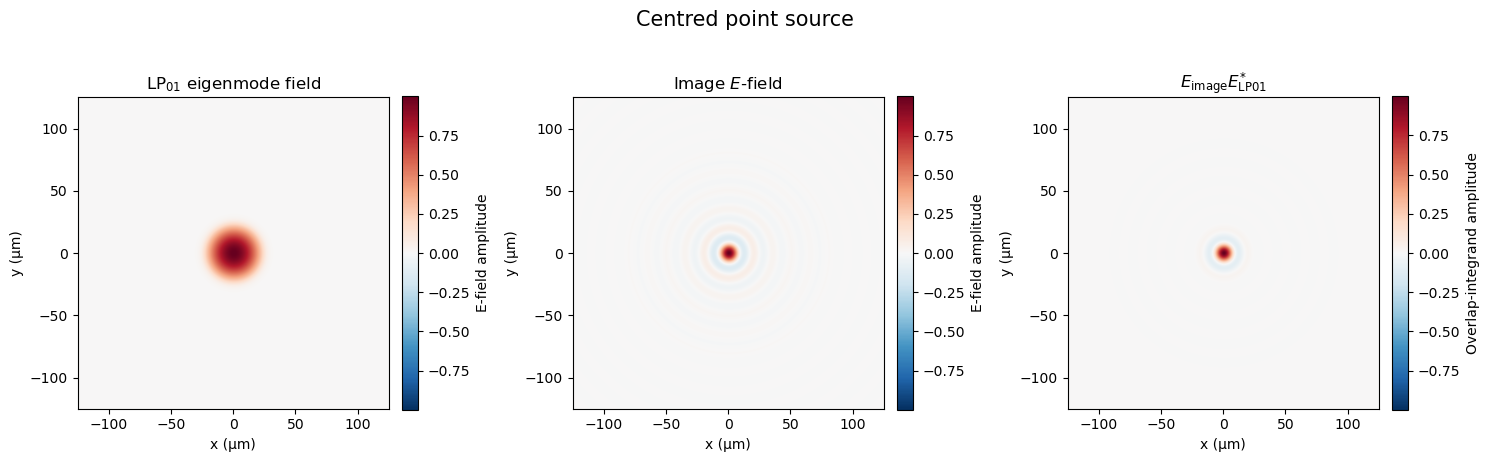

In [49]:
plot_overlap_case(
    E_LP01,
    E_psf_centred,
    overlap_centred,
    title="Centred point source"
)

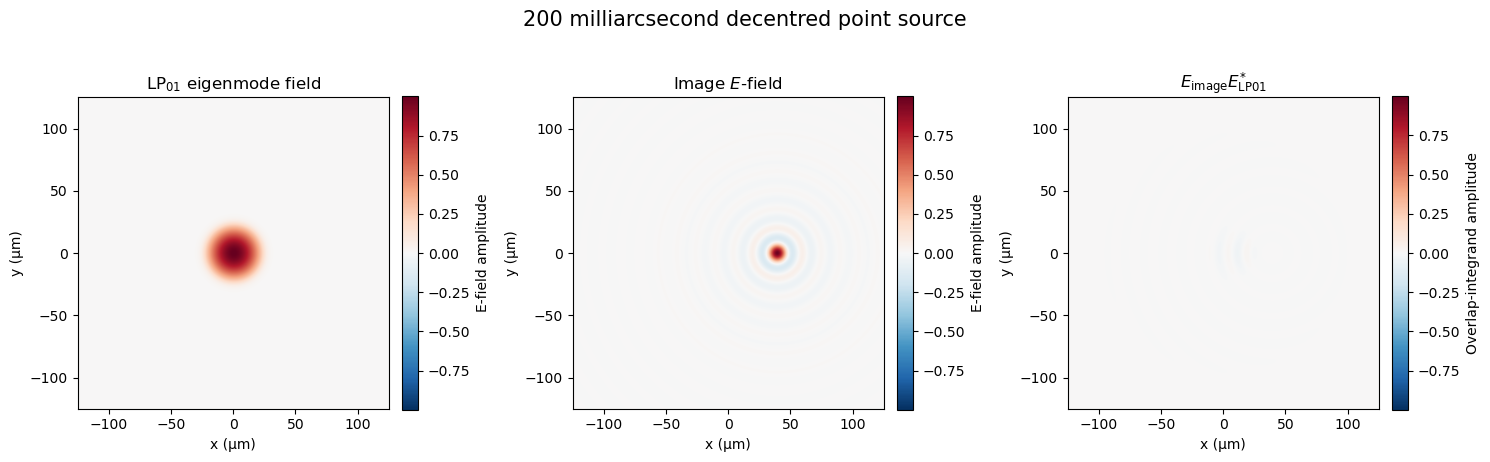

In [51]:
plot_overlap_case(
    E_LP01,
    E_psf_decentred,
    overlap_decentred,
    title="200 milliarcsecond decentred point source"
)

In [52]:
def eta_psf_2d_decentre_map(
        prepared_modes,
        x, y, x_1d, y_1d,
        lam0, F_eff, alpha,
        decentre_x_1d,
        decentre_y_1d,
        E_S=1.0,
        return_mode_maps=False,
        n_jobs=1
):
    """
    Calculate point-source coupling efficiency over a 2D grid of
    PSF decentre positions relative to the fibre centre.

    Parameters
    ----------
    prepared_modes : list
        Output from prepare_modes_2d() for ONE fibre core radius.

    x, y : 2D arrays
        Coordinate grids at the fibre input plane [m].

    x_1d, y_1d : 1D arrays
        Coordinate axes corresponding to x and y [m].

    lam0 : float
        Wavelength [m].

    F_eff : float
        Effective focal ratio.

    alpha : float
        Central obstruction ratio.

    decentre_x_1d : 1D array
        PSF x-offset positions [m].

    decentre_y_1d : 1D array
        PSF y-offset positions [m].

    E_S : float
        Source electric-field amplitude.

    return_mode_maps : bool
        If True, also store a 2D eta map for each individual mode.

    n_jobs : int
        Number of parallel workers.

    Returns
    -------
    eta_total_map : 2D ndarray
        Total coupling efficiency at every (dx, dy).

        Shape:
            (len(decentre_y_1d), len(decentre_x_1d))

    mode_eta_maps : dict or None
        If return_mode_maps=True, dictionary containing the
        coupling map for each individual mode.
    """

    nx = len(decentre_x_1d)
    ny = len(decentre_y_1d)

    # ---------------------------------------------------------
    # Prepare storage for individual mode maps if requested
    # ---------------------------------------------------------
    if return_mode_maps:

        mode_eta_maps = {}

        for mode in prepared_modes:

            key = (
                mode["l"],
                mode["m"],
                mode["angular"]
            )

            mode_eta_maps[key] = np.zeros((ny, nx))

    else:
        mode_eta_maps = None

    # ---------------------------------------------------------
    # Calculate one horizontal row of the decentre map
    # ---------------------------------------------------------
    def calculate_row(dy):

        eta_row = np.zeros(nx)

        if return_mode_maps:
            mode_rows = {
                key: np.zeros(nx)
                for key in mode_eta_maps.keys()
            }
        else:
            mode_rows = None

        for ix, dx in enumerate(decentre_x_1d):

            eta_total, mode_results = total_eff_2d(
                prepared_modes=prepared_modes,
                x=x,
                y=y,
                x_1d=x_1d,
                y_1d=y_1d,
                lam0=lam0,
                F_eff=F_eff,
                alpha=alpha,
                decentre=(dx, dy),
                E_S=E_S
            )

            eta_row[ix] = eta_total

            if return_mode_maps:

                for result in mode_results:

                    key = (
                        result["l"],
                        result["m"],
                        result["angular"]
                    )

                    mode_rows[key][ix] = result["eta"]

        return eta_row, mode_rows

    # ---------------------------------------------------------
    # Calculate every y row
    # ---------------------------------------------------------
    if n_jobs == 1:

        eta_total_map = np.zeros((ny, nx))

        for iy, dy in enumerate(decentre_y_1d):

            eta_row, mode_rows = calculate_row(dy)

            eta_total_map[iy, :] = eta_row

            if return_mode_maps:

                for key in mode_eta_maps:
                    mode_eta_maps[key][iy, :] = mode_rows[key]

            print(
                f"{iy + 1}/{ny} rows complete "
                f"({100 * (iy + 1) / ny:.1f}%)"
            )

    else:

        results = Parallel(
            n_jobs=n_jobs,
            verbose=10
        )(
            delayed(calculate_row)(dy)
            for dy in decentre_y_1d
        )

        eta_total_map = np.array(
            [result[0] for result in results]
        )

        if return_mode_maps:

            for key in mode_eta_maps:

                mode_eta_maps[key] = np.array([
                    result[1][key]
                    for result in results
                ])

    return eta_total_map, mode_eta_maps

In [53]:
decentre_max = 25e-6

decentre_x_1d = np.linspace(
    -decentre_max,
    decentre_max,
    100
)

decentre_y_1d = np.linspace(
    -decentre_max,
    decentre_max,
    100
)

In [54]:
eta_map_25micron, mode_maps_25micron = eta_psf_2d_decentre_map(
    prepared_modes_25microns,

    x, y,
    x_1d, y_1d,

    lam0=1.5e-6,
    F_eff=5,
    alpha=0.125,

    decentre_x_1d=decentre_x_1d,
    decentre_y_1d=decentre_y_1d,

    return_mode_maps=True,

    n_jobs=4
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:  2.0min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  3.1min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  6.1min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  7.7min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed: 12.2min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed: 15.1min
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed: 19.6min
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed: 22.9min
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed: 28.4min
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed: 32.7min
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed: 35.5min finished


In [55]:
eta_map_25micron.shape

(100, 100)

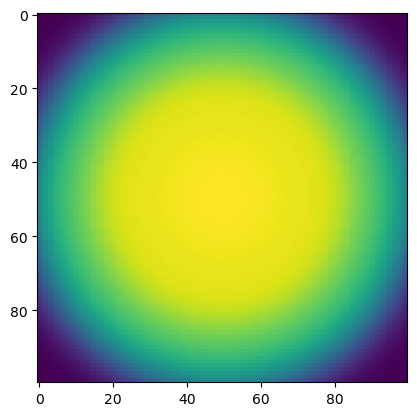

In [56]:
plt.imshow(eta_map_25micron)

In [57]:
def plot_eta_map(eta_map, decentre_x_1d, decentre_y_1d, title):
    plt.figure(figsize=(7, 6))

    plt.imshow(
        eta_map,
        extent=[
            decentre_x_1d.min() * 1e6,
            decentre_x_1d.max() * 1e6,
            decentre_y_1d.min() * 1e6,
            decentre_y_1d.max() * 1e6
        ],
        origin="lower",
        aspect="equal"
    )

    plt.colorbar(label=r"Coupling efficiency, $\eta$")
    plt.xlabel(r"$\Delta x$ (µm)")
    plt.ylabel(r"$\Delta y$ (µm)")
    plt.title(title)
    plt.minorticks_on()
    plt.show()

In [58]:
eta_LP11_cos_map = mode_maps_25micron[(1, 1, "cos")]
eta_LP11_sin_map = mode_maps_25micron[(1, 1, "sin")]

eta_LP21_cos_map = mode_maps_25micron[(2, 1, "cos")]
eta_LP21_sin_map = mode_maps_25micron[(2, 1, "sin")]

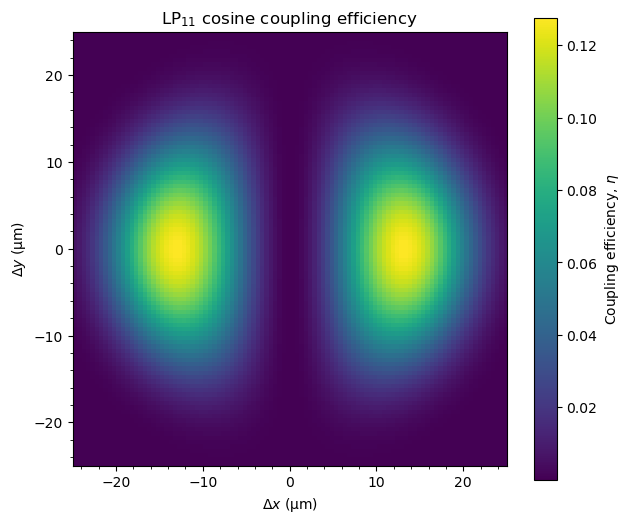

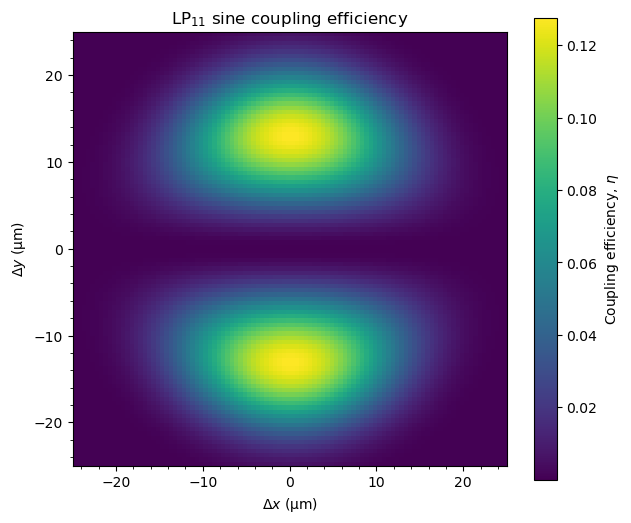

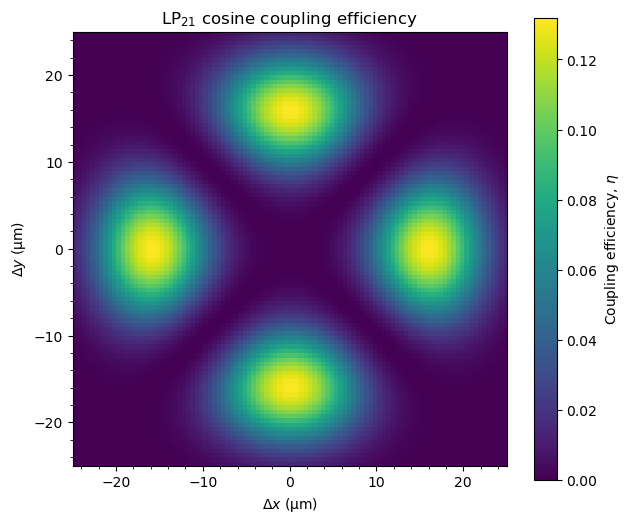

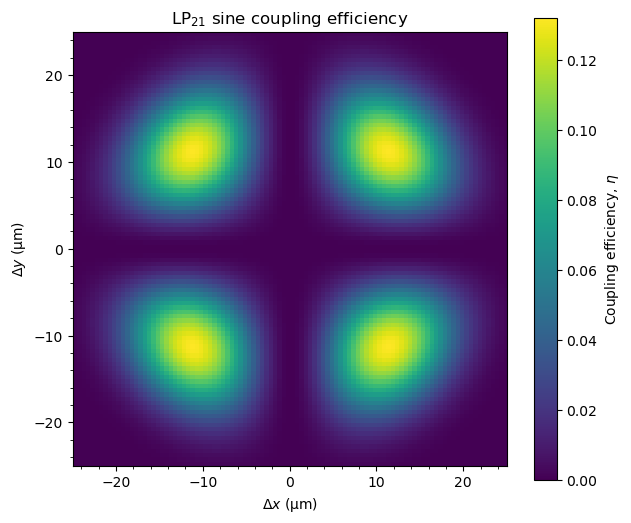

In [59]:
plot_eta_map(
    eta_LP11_cos_map,
    decentre_x_1d,
    decentre_y_1d,
    r"LP$_{11}$ cosine coupling efficiency"
)

plot_eta_map(
    eta_LP11_sin_map,
    decentre_x_1d,
    decentre_y_1d,
    r"LP$_{11}$ sine coupling efficiency"
)

plot_eta_map(
    eta_LP21_cos_map,
    decentre_x_1d,
    decentre_y_1d,
    r"LP$_{21}$ cosine coupling efficiency"
)

plot_eta_map(
    eta_LP21_sin_map,
    decentre_x_1d,
    decentre_y_1d,
    r"LP$_{21}$ sine coupling efficiency"
)

In [60]:
eta_LP11_map = eta_LP11_cos_map + eta_LP11_sin_map
eta_LP21_map = eta_LP21_cos_map + eta_LP21_sin_map

In [61]:
eta_LP21_map.shape

(100, 100)

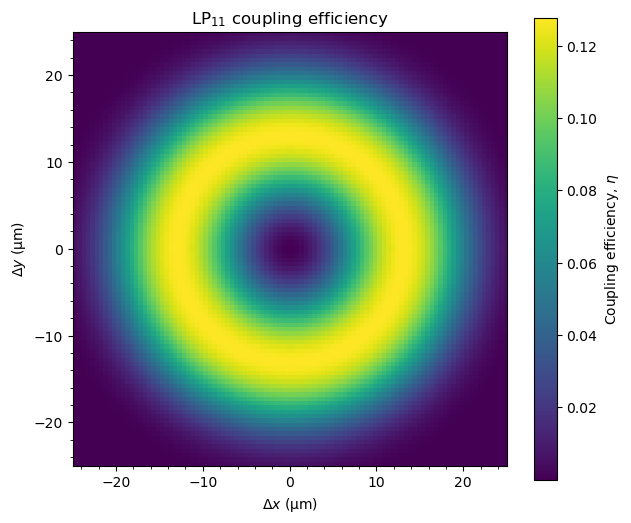

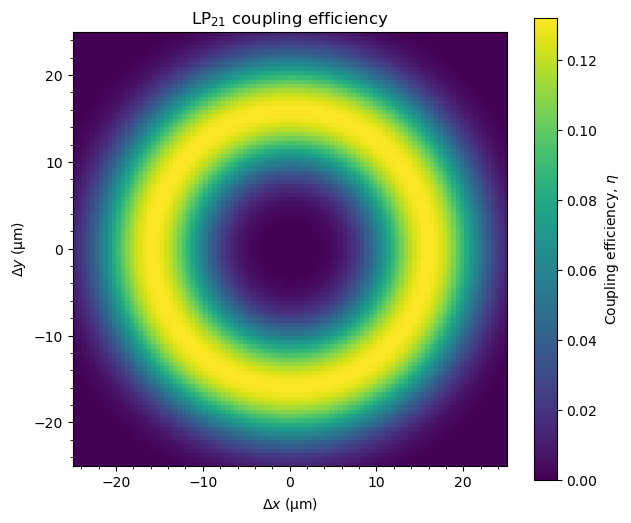

In [62]:
plot_eta_map(
    eta_LP11_map,
    decentre_x_1d,
    decentre_y_1d,
    r"LP$_{11}$ coupling efficiency"
)

plot_eta_map(
    eta_LP21_map,
    decentre_x_1d,
    decentre_y_1d,
    r"LP$_{21}$ coupling efficiency"
)

In [63]:
import matplotlib.pyplot as plt
import numpy as np

def plot_selected_asymmetric_mode_family_maps(
    mode_maps,
    decentre_x_1d,
    decentre_y_1d,
    families,
    cmap="viridis",
    same_scale_per_row=True
):
    """
    Plot cos, sin, and total eta maps for selected asymmetric mode families,
    with one colorbar per row.
    """

    nrows = len(families)

    fig = plt.figure(figsize=(15, 4.2 * nrows))
    gs = fig.add_gridspec(
        nrows=nrows,
        ncols=4,
        width_ratios=[1, 1, 1, 0.05],   # last column for colorbar
        wspace=0.25,
        hspace=0.35
    )

    extent = [
        decentre_x_1d.min() * 1e6,
        decentre_x_1d.max() * 1e6,
        decentre_y_1d.min() * 1e6,
        decentre_y_1d.max() * 1e6
    ]

    for i, (l, m) in enumerate(families):

        eta_cos = mode_maps[(l, m, "cos")]
        eta_sin = mode_maps[(l, m, "sin")]
        eta_total = eta_cos + eta_sin

        maps = [eta_cos, eta_sin, eta_total]
        titles = [
            rf"LP$_{{{l}{m}}}$ cosine",
            rf"LP$_{{{l}{m}}}$ sine",
            rf"LP$_{{{l}{m}}}$ total"
        ]

        if same_scale_per_row:
            vmin = 0.0
            vmax = max(np.max(eta_cos), np.max(eta_sin), np.max(eta_total))
        else:
            vmin = None
            vmax = None

        row_axes = []
        im = None

        for j in range(3):
            ax = fig.add_subplot(gs[i, j])
            row_axes.append(ax)

            im = ax.imshow(
                maps[j],
                extent=extent,
                origin="lower",
                aspect="equal",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax
            )

            ax.set_title(titles[j])
            ax.set_xlabel(r"$\Delta x$ (µm)")
            ax.set_ylabel(r"$\Delta y$ (µm)")
            ax.minorticks_on()

        # dedicated colorbar axis for this row
        cax = fig.add_subplot(gs[i, 3])
        cbar = fig.colorbar(im, cax=cax)
        cbar.set_label(r"Coupling efficiency, $\eta$")

    plt.show()

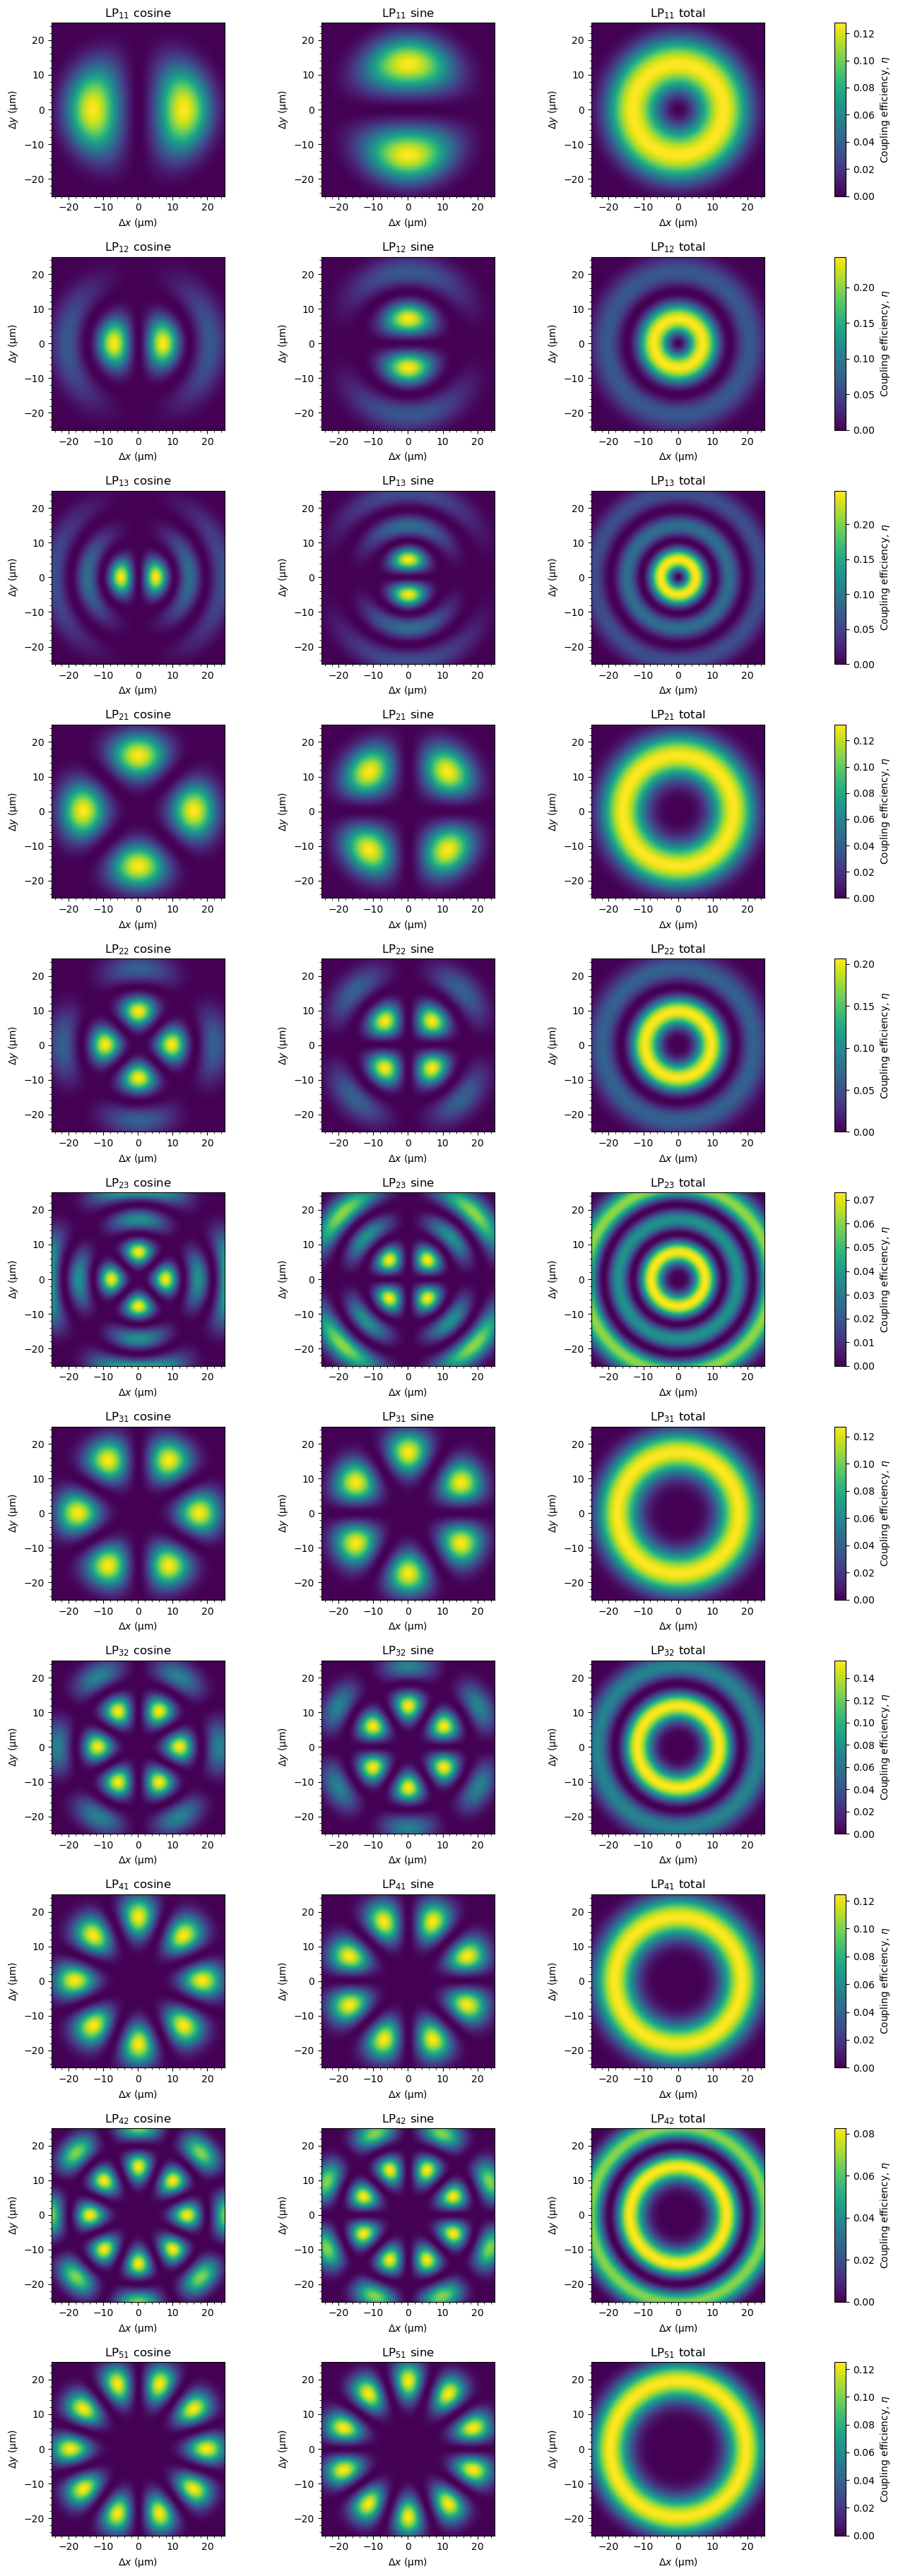

In [64]:
plot_selected_asymmetric_mode_family_maps(
    mode_maps_25micron,
    decentre_x_1d,
    decentre_y_1d,
    families=sorted({(l, m)
    for (l, m, angular) in mode_maps_25micron.keys()
    if l != 0})
)

In [65]:
90/4

22.5

In [66]:
90/5

18.0

In [67]:
def extended_source_no_opt_efficiency_at_one_radius_2d(
        a,
        x, y, x_1d, y_1d, 
        NA, lam0, I_source, 
        F_eff, 
        alpha=0.0, 
        az_sym=True, 
        mode_case="smf", 
        decentre_max="core_radius", 
        n_decentre=50, E_S=1.0, 
        n_F_grid=60, 
):
    """
    For one fibre core radius a: 
        1. Prepare fibre modes
        2. Calculate eta_psf(d)
        3. Integrate eta_psf(d) to get coupling effieciency for an extended source with a given brightness distribution

    Parameters:
    decentre_max: the maximum decentre radius, set to None, but equals to the cladding radius
    n_decentre: the number of decentre points to consider
    E_S: the electric field amplitude of the point source
    n_F_grid: the number of grid points for the F_eff calculation
    I_source: the intensity distribution of the extended source, 2d numpy array, same shape as x and y grids

    """

    V = 2 * np.pi * a * NA / lam0

    prepared_modes = prepare_modes_2d(
        x, y, 
        a=a, 
        NA=NA, 
        lam0=lam0,
        az_sym=az_sym, 
        mode_case=mode_case
    )

    eta_centre, mode_results_centred = total_eff_2d(
        prepared_modes,
        x=x, y=y, x_1d=x_1d, y_1d=y_1d,
        lam0=lam0,
        F_eff=F_eff,
        alpha=alpha,
        decentre=None,
        E_S=E_S
    )

    E_image_opt, I_image_opt = diffraction_limited_E_field_at_fibre_2d(
        x, y,
        lam0=lam0,
        F_eff=F_eff,
        alpha=alpha,
        E_S=E_S,
        decentre=None
    )

    # Choose decentre_max to be the cladding radius if not specified
    if decentre_max is None: 
        r_max = 125e-6 # in meters, this is the maximum radius of the grid we prepared for the field calculations, so we can't go beyond this
        decentre_max = r_max # cladding radius 

    elif decentre_max == "core_radius": 
        decentre_max = a # core radius

    decentre_array = np.linspace(0, decentre_max, n_decentre)

    # Calculate eta_psf(d) for the range of decentre values
    eta_psf,  mode_results_decentre = eta_psf_vs_radial_decentre_position(
        prepared_modes, 
        x, y, x_1d, y_1d,
        lam0=lam0, F_eff=F_eff, alpha=alpha,
        decentre_array=decentre_array,
        E_S=E_S
    )

    # Integrate over the extended source brightness distribution to get the coupling efficiency for the extended source
    eta_map_2d=radial_efficiency_to_2d(decentre_array, eta_psf, x, y)

    eta_extended_source = eta_extended_source_2d(eta_map_2d=eta_map_2d,
        galaxy_brightness_2d=I_source, x_1d=x_1d, y_1d=y_1d)
    
    return {
        "a": a,
        "V": V,
        "F_eff": F_eff,
        "eta_centre": eta_centre,
        "eta_extended_source": eta_extended_source,
        "decentre_array": decentre_array,
        "eta_psf": eta_psf,
        "mode_results_centred": mode_results_centred,
        "mode_results_decentre": mode_results_decentre,
        "E_image_opt": E_image_opt,
        "I_image_opt": I_image_opt
    }

In [68]:
# wavelength of beam in vacuum
lam0 = 1.5e-6 
# fibre core radius
a = 5e-6 
# numerical aperture of fibre
NA = 0.1 

# Calculate the normalised frequency (V-number) of the fibre
V = 2 * pi * (a / lam0) * NA
print(f"V-number of the fibre: {V:.2f}")

V-number of the fibre: 2.09


In [69]:
n_sersic = 3.335 # sersic index, n>0.36
Re_arcsec = 0.101 # half light radius in arcseconds
q_param = 0.514 # projected axis ratio of the galaxy, b/a, where b is the semi-minor axis and a is the semi-major axis. This is used to calculate the effective radius in the direction of the fibre input plane.
# PA = 0 # assumed to be 0 for simplicity, but can be adjusted based on the orientation of the galaxy in the sky.
PA_deg = -88.7
ellip = 1 - q_param # ellipticity of the galaxy, defined as 1 - (b/a)

In [70]:
# Sersic profile has a scaling constant b_n, for n>0.36, b_n can be approximated as b_n = 2n - 1/3 + 4/(405n) + 46/(25515n^2) + 131/(1148175n^3) 
# - 2194697/(30690717750n^4)
b_n = 2 * n_sersic - 1/3 + 4/(405*n_sersic) + 46/(25515*n_sersic**2) + 131/(1148175*n_sersic**3) - 2194697/(30690717750*n_sersic**4)

In [71]:
NA = 0.1
F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))
Magnification = F_fibre / 49.9
F_focus = 49.9

D_M1 = 8.0 # Diameter of the primary mirror in meters
D_obstruction = 1.0 # Diameter of the central obstruction in meters
alpha_vlt = D_obstruction / D_M1 # Ratio of the central obstruction to the primary mirror diameter (0.125 for VLT)
rad_to_arcsec = (180 / np.pi) * 3600
plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)  # arcsec / metre at telescope focal plane
plate_scale_demag = plate_scale_coude / Magnification # arcsec / metre at the demagnified fibre input plane

In [72]:
def radius_metre_to_arcsec(image_radius_metre, plate_scale):
    """
    Convert a distance in metres at the fibre input plane to arcseconds on the sky.
    """
    FOV_arcsec = plate_scale * 2 * image_radius_metre

    return FOV_arcsec

In [73]:
angular_extent_25micron = radius_metre_to_arcsec(25e-6, plate_scale_demag)
angular_extent_25micron

np.float64(0.259129912794308)

In [74]:
n_grid

1000

In [75]:
n_grid_100 = 100

In [76]:
x_arcsec_1d = np.linspace(-angular_extent_25micron, angular_extent_25micron, 100)
y_arcsec_1d = np.linspace(-angular_extent_25micron, angular_extent_25micron, 100)

x_arcsec, y_arcsec = np.meshgrid(x_arcsec_1d, y_arcsec_1d)

In [77]:
x_arcsec.shape

(100, 100)

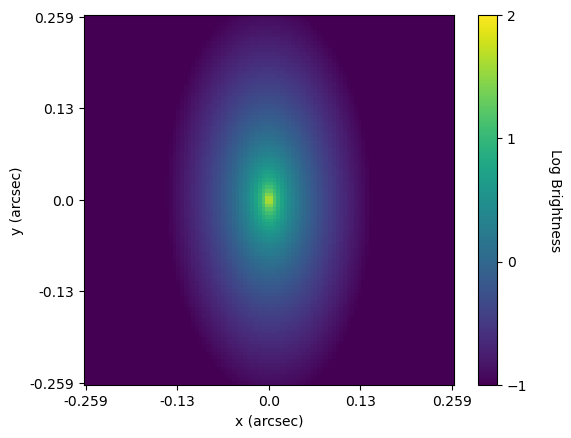

In [78]:
model_cent = Sersic2D(amplitude=1, r_eff = Re_arcsec, n = n_sersic, x_0=0, y_0=0, ellip=ellip, theta=np.radians(PA_deg))

# img is a numpy array of the Sersic profile evaluated at each point in the 2D grid defined by x_arcsec and y_arcsec. 
img = model_cent(x_arcsec, y_arcsec)
log_img = np.log10(img)

fig, ax = plt.subplots()
im = ax.imshow(log_img, origin='lower', interpolation='nearest',
               vmin=-1, vmax=2)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Log Brightness', rotation=270, labelpad=25)
# Set ticks in arcseconds for the x and y axes
ax.set_xticks(np.linspace(0, n_grid_100-1, 5))
ax.set_xticklabels(np.round(np.linspace(-angular_extent_25micron, angular_extent_25micron, 5), 3))
ax.set_yticks(np.linspace(0, n_grid_100-1, 5))
ax.set_yticklabels(np.round(np.linspace(-angular_extent_25micron, angular_extent_25micron, 5), 3))
cbar.set_ticks([-1, 0, 1, 2])
plt.xlabel('x (arcsec)')
plt.ylabel('y (arcsec)')
plt.show()

In [79]:
print(x.shape, y.shape, img.shape)

(1000, 1000) (1000, 1000) (100, 100)


In [80]:
x_1d_100grid = np.linspace(-25e-6, 25e-6, 100)
y_1d_100grid = np.linspace(-25e-6, 25e-6, 100)

x_100, y_100 = np.meshgrid(x_1d_100grid, y_1d_100grid)

In [81]:
extended_source_no_opt_efficiency_at_one_radius_2d(
        a=25e-6, 
        x=x_100, y=y_100, x_1d=x_1d_100grid, y_1d=y_1d_100grid, 
        NA=0.1, lam0=1.5e-6, I_source=img, 
        F_eff=F_fibre, 
        alpha=0.0, 
        az_sym=False, 
        mode_case="few_mode", 
        decentre_max=None, 
        n_decentre=50, E_S=1.0, 
        n_F_grid=60, 
)

{'a': 2.5e-05,
 'V': 10.471975511965978,
 'F_eff': np.float64(4.9749371855331),
 'eta_centre': np.float64(1.0356145718385825),
 'eta_extended_source': np.float64(0.9710256878227291),
 'decentre_array': array([0.00000000e+00, 2.55102041e-06, 5.10204082e-06, 7.65306122e-06,
        1.02040816e-05, 1.27551020e-05, 1.53061224e-05, 1.78571429e-05,
        2.04081633e-05, 2.29591837e-05, 2.55102041e-05, 2.80612245e-05,
        3.06122449e-05, 3.31632653e-05, 3.57142857e-05, 3.82653061e-05,
        4.08163265e-05, 4.33673469e-05, 4.59183673e-05, 4.84693878e-05,
        5.10204082e-05, 5.35714286e-05, 5.61224490e-05, 5.86734694e-05,
        6.12244898e-05, 6.37755102e-05, 6.63265306e-05, 6.88775510e-05,
        7.14285714e-05, 7.39795918e-05, 7.65306122e-05, 7.90816327e-05,
        8.16326531e-05, 8.41836735e-05, 8.67346939e-05, 8.92857143e-05,
        9.18367347e-05, 9.43877551e-05, 9.69387755e-05, 9.94897959e-05,
        1.02040816e-04, 1.04591837e-04, 1.07142857e-04, 1.09693878e-04,
       

In [82]:
def test_radial_isotropy(
        prepared_modes,
        x, y, x_1d, y_1d,
        lam0,
        F_eff,
        alpha,
        radius_array,
        angle_array,
        E_S=1.0
):
    """
    Explicitly calculate coupling efficiency at many (r, theta)
    positions to test radial isotropy.

    Returns
    -------
    results : dict

        results["families"][(l,m)]["cos"]
            shape = (n_radius, n_angle)

        results["families"][(l,m)]["sin"]
            shape = (n_radius, n_angle)

        results["families"][(l,m)]["total"]
            cos + sin for l != 0

        results["total_all_modes"]
            total coupling efficiency summed over all prepared modes
            shape = (n_radius, n_angle)
    """

    nr = len(radius_array)
    nt = len(angle_array)

    # Unique LP families
    families = sorted({
        (mode["l"], mode["m"])
        for mode in prepared_modes
    })

    results = {
        "radius_array": np.asarray(radius_array),
        "angle_array": np.asarray(angle_array),
        "families": {},
        "total_all_modes": np.zeros((nr, nt))
    }

    # Prepare storage
    for l, m in families:

        if l == 0:
            results["families"][(l, m)] = {
                "symmetric": np.zeros((nr, nt)),
                "total": np.zeros((nr, nt))
            }

        else:
            results["families"][(l, m)] = {
                "cos": np.zeros((nr, nt)),
                "sin": np.zeros((nr, nt)),
                "total": np.zeros((nr, nt))
            }

    # --------------------------------------------------
    # Explicitly evaluate every r and theta
    # --------------------------------------------------
    for ir, r in enumerate(radius_array):

        for itheta, theta in enumerate(angle_array):

            dx = r * np.cos(theta)
            dy = r * np.sin(theta)

            eta_total, mode_results = total_eff_2d(
                prepared_modes=prepared_modes,
                x=x,
                y=y,
                x_1d=x_1d,
                y_1d=y_1d,
                lam0=lam0,
                F_eff=F_eff,
                alpha=alpha,
                decentre=(dx, dy),
                E_S=E_S
            )

            results["total_all_modes"][ir, itheta] = eta_total

            # Store individual modal eta
            for mode in mode_results:

                l = mode["l"]
                m = mode["m"]
                angular = mode["angular"]
                eta = mode["eta"]

                if l == 0:

                    results["families"][(l, m)]["symmetric"][
                        ir, itheta
                    ] = eta

                else:

                    results["families"][(l, m)][angular][
                        ir, itheta
                    ] = eta

        # Construct family totals after all angles at this radius
        for l, m in families:

            if l == 0:

                results["families"][(l, m)]["total"][ir, :] = (
                    results["families"][(l, m)]["symmetric"][ir, :]
                )

            else:

                results["families"][(l, m)]["total"][ir, :] = (
                    results["families"][(l, m)]["cos"][ir, :]
                    +
                    results["families"][(l, m)]["sin"][ir, :]
                )

        print(
            f"{ir + 1}/{nr} radii complete "
            f"({100 * (ir + 1) / nr:.1f}%)"
        )

    return results

In [83]:
radius_test = np.linspace(
    0,
    25e-6,
    21
)

angle_test = np.linspace(
    0,
    2 * np.pi,
    72,
    endpoint=False
)

In [84]:
radius_test

array([0.000e+00, 1.250e-06, 2.500e-06, 3.750e-06, 5.000e-06, 6.250e-06,
       7.500e-06, 8.750e-06, 1.000e-05, 1.125e-05, 1.250e-05, 1.375e-05,
       1.500e-05, 1.625e-05, 1.750e-05, 1.875e-05, 2.000e-05, 2.125e-05,
       2.250e-05, 2.375e-05, 2.500e-05])

In [85]:
angle_test*180 / np.pi

array([  0.,   5.,  10.,  15.,  20.,  25.,  30.,  35.,  40.,  45.,  50.,
        55.,  60.,  65.,  70.,  75.,  80.,  85.,  90.,  95., 100., 105.,
       110., 115., 120., 125., 130., 135., 140., 145., 150., 155., 160.,
       165., 170., 175., 180., 185., 190., 195., 200., 205., 210., 215.,
       220., 225., 230., 235., 240., 245., 250., 255., 260., 265., 270.,
       275., 280., 285., 290., 295., 300., 305., 310., 315., 320., 325.,
       330., 335., 340., 345., 350., 355.])

In [86]:
isotropy_results = test_radial_isotropy(
    prepared_modes_25microns,
    x, y,
    x_1d, y_1d,
    lam0=1.5e-6,
    F_eff=F_fibre,
    alpha=0.0,
    radius_array=radius_test,
    angle_array=angle_test
)

1/21 radii complete (4.8%)
2/21 radii complete (9.5%)
3/21 radii complete (14.3%)
4/21 radii complete (19.0%)
5/21 radii complete (23.8%)
6/21 radii complete (28.6%)
7/21 radii complete (33.3%)
8/21 radii complete (38.1%)
9/21 radii complete (42.9%)
10/21 radii complete (47.6%)
11/21 radii complete (52.4%)
12/21 radii complete (57.1%)
13/21 radii complete (61.9%)
14/21 radii complete (66.7%)
15/21 radii complete (71.4%)
16/21 radii complete (76.2%)
17/21 radii complete (81.0%)
18/21 radii complete (85.7%)
19/21 radii complete (90.5%)
20/21 radii complete (95.2%)
21/21 radii complete (100.0%)


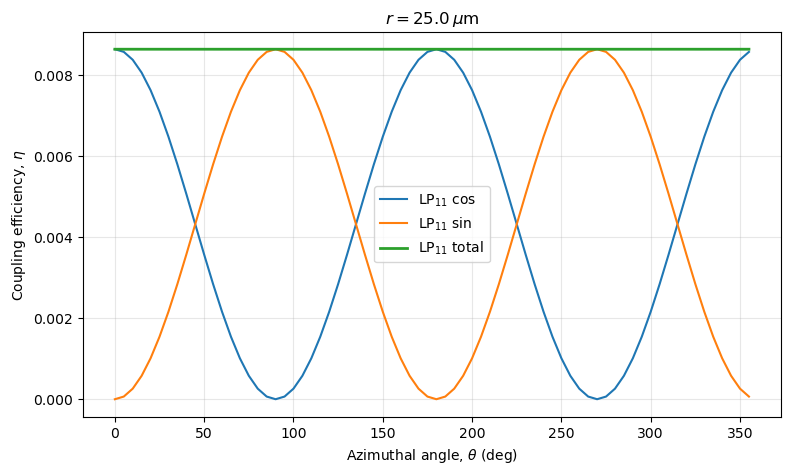

In [87]:
ir = -1

theta_deg = np.degrees(
    isotropy_results["angle_array"]
)

family = isotropy_results["families"][(1, 1)]

plt.figure(figsize=(9, 5))

plt.plot(
    theta_deg,
    family["cos"][ir],
    label=r"LP$_{11}$ cos"
)

plt.plot(
    theta_deg,
    family["sin"][ir],
    label=r"LP$_{11}$ sin"
)

plt.plot(
    theta_deg,
    family["total"][ir],
    label=r"LP$_{11}$ total",
    linewidth=2
)

plt.xlabel(r"Azimuthal angle, $\theta$ (deg)")
plt.ylabel(r"Coupling efficiency, $\eta$")

plt.title(
    rf"$r={radius_test[ir] * 1e6:.1f}\,\mu$m"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [88]:
# from ipywidgets import interact, FloatSlider
# import numpy as np
# import matplotlib.pyplot as plt

# theta_deg = np.degrees(
#     isotropy_results["angle_array"]
# )

# family = isotropy_results["families"][(1, 1)]


# def plot_LP11_isotropy(radius_um):

#     # Find the radius_test index closest to slider value
#     ir = np.argmin(
#         np.abs(radius_test * 1e6 - radius_um)
#     )

#     plt.figure(figsize=(9, 5))

#     plt.plot(
#         theta_deg,
#         family["cos"][ir],
#         label=r"LP$_{11}$ cos"
#     )

#     plt.plot(
#         theta_deg,
#         family["sin"][ir],
#         label=r"LP$_{11}$ sin"
#     )

#     plt.plot(
#         theta_deg,
#         family["total"][ir],
#         label=r"LP$_{11}$ total",
#         linewidth=2
#     )

#     plt.xlabel(r"Azimuthal angle, $\theta$ (deg)")
#     plt.ylabel(r"Coupling efficiency, $\eta$")

#     plt.title(
#         rf"LP$_{{11}}$, "
#         rf"$r={radius_test[ir] * 1e6:.2f}\,\mu$m"
#     )

#     plt.xlim(0, 360)

#     plt.legend()
#     plt.grid(alpha=0.3)
#     plt.show()


# interact(
#     plot_LP11_isotropy,
#     radius_um=FloatSlider(
#         value=25.0,
#         min=0.0,
#         max=25.0,
#         step=1.25,
#         description=r"$r$ (µm):",
#         continuous_update=False
#     )
# )

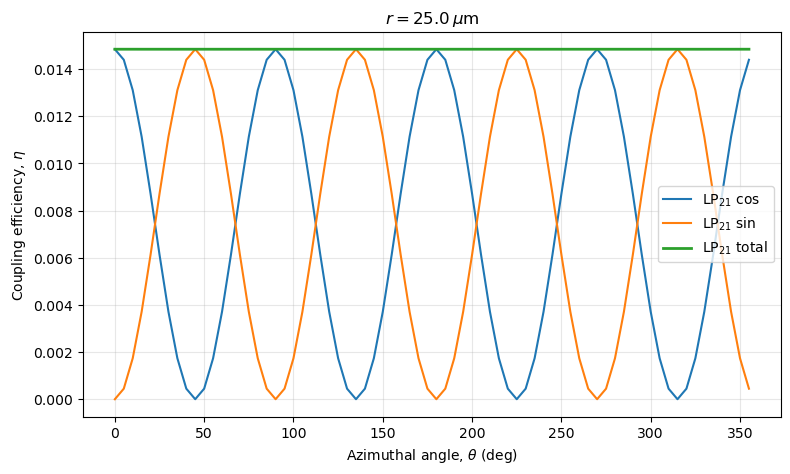

In [89]:
ir = -1

theta_deg = np.degrees(
    isotropy_results["angle_array"]
)

family = isotropy_results["families"][(2, 1)]

plt.figure(figsize=(9, 5))

plt.plot(
    theta_deg,
    family["cos"][ir],
    label=r"LP$_{21}$ cos"
)

plt.plot(
    theta_deg,
    family["sin"][ir],
    label=r"LP$_{21}$ sin"
)

plt.plot(
    theta_deg,
    family["total"][ir],
    label=r"LP$_{21}$ total",
    linewidth=2
)

plt.xlabel(r"Azimuthal angle, $\theta$ (deg)")
plt.ylabel(r"Coupling efficiency, $\eta$")

plt.title(
    rf"$r={radius_test[ir] * 1e6:.1f}\,\mu$m"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [90]:
def fractional_angular_variation(eta_theta):
    """
    Fractional peak-to-peak variation about the angular mean.
    """

    mean_eta = np.mean(eta_theta)

    if np.isclose(mean_eta, 0.0):
        return np.nan

    return (
        np.max(eta_theta) - np.min(eta_theta)
    ) / mean_eta

In [91]:
lp11_variation = np.array([
    fractional_angular_variation(
        isotropy_results["families"][(1, 1)]["total"][ir]
    )
    for ir in range(len(radius_test))
])

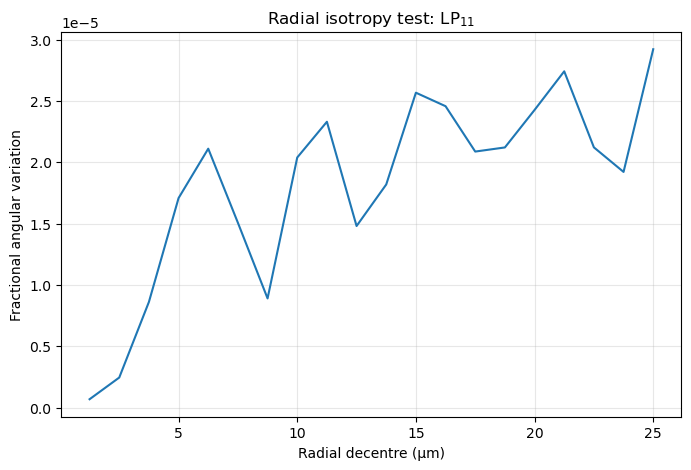

In [92]:
plt.figure(figsize=(8, 5))

plt.plot(
    radius_test * 1e6,
    lp11_variation
)

plt.xlabel("Radial decentre (µm)")
plt.ylabel("Fractional angular variation")
plt.title(r"Radial isotropy test: LP$_{11}$")
plt.grid(alpha=0.3)

plt.show()

In [93]:
lp21_variation = np.array([
    fractional_angular_variation(
        isotropy_results["families"][(2, 1)]["total"][ir]
    )
    for ir in range(len(radius_test))
])

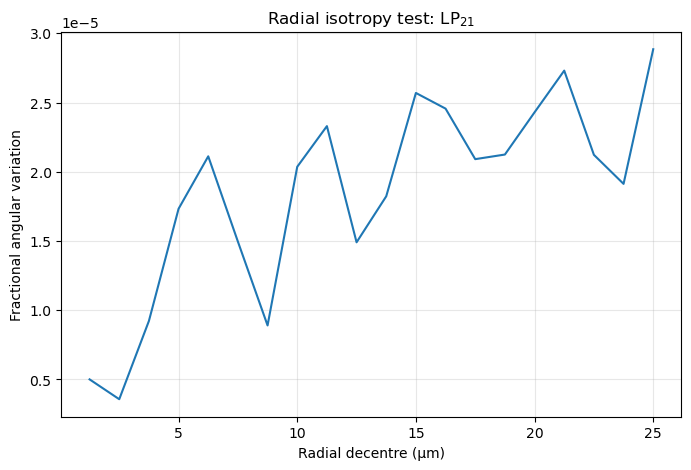

In [94]:
plt.figure(figsize=(8, 5))

plt.plot(
    radius_test * 1e6,
    lp21_variation
)

plt.xlabel("Radial decentre (µm)")
plt.ylabel("Fractional angular variation")
plt.title(r"Radial isotropy test: LP$_{21}$")
plt.grid(alpha=0.3)

plt.show()

In [95]:
lp11_variation = np.array([
    fractional_angular_variation(
        isotropy_results["families"][(1, 1)]["total"][ir]
    )
    for ir in range(len(radius_test))
])


lp21_variation = np.array([
    fractional_angular_variation(
        isotropy_results["families"][(2, 1)]["total"][ir]
    )
    for ir in range(len(radius_test))
])


total_variation = np.array([
    fractional_angular_variation(
        isotropy_results["total_all_modes"][ir]
    )
    for ir in range(len(radius_test))
])

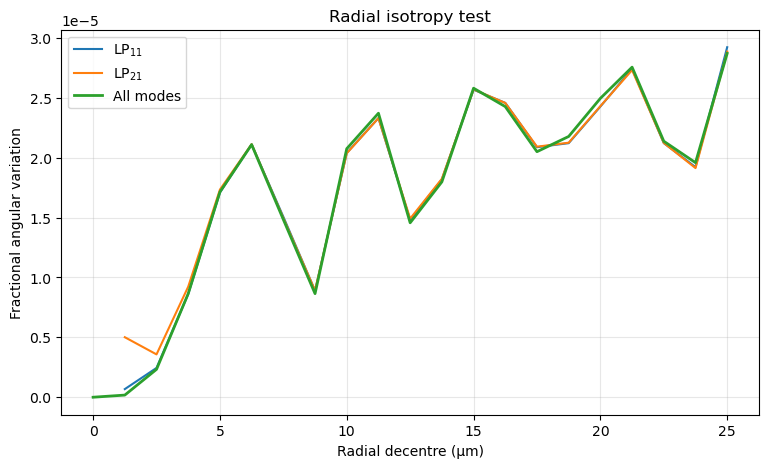

In [96]:
plt.figure(figsize=(9, 5))

plt.plot(
    radius_test * 1e6,
    lp11_variation,
    label=r"LP$_{11}$"
)

plt.plot(
    radius_test * 1e6,
    lp21_variation,
    label=r"LP$_{21}$"
)

plt.plot(
    radius_test * 1e6,
    total_variation,
    label="All modes",
    linewidth=2
)

plt.xlabel("Radial decentre (µm)")
plt.ylabel("Fractional angular variation")

plt.title(
    "Radial isotropy test"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

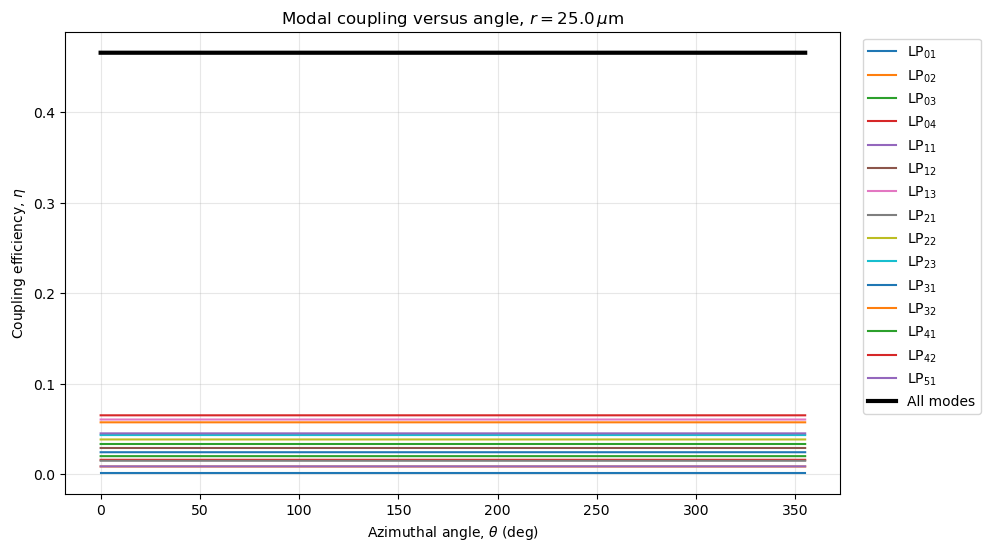

In [97]:
plt.figure(figsize=(10, 6))

for (l, m), family in isotropy_results["families"].items():

    plt.plot(
        theta_deg,
        family["total"][ir],
        label=rf"LP$_{{{l}{m}}}$"
    )

# Total over absolutely all modes
plt.plot(
    theta_deg,
    isotropy_results["total_all_modes"][ir],
    linewidth=3,
    color="black",
    label="All modes"
)

plt.xlabel(r"Azimuthal angle, $\theta$ (deg)")
plt.ylabel(r"Coupling efficiency, $\eta$")

plt.title(
    rf"Modal coupling versus angle, "
    rf"$r={radius_test[ir] * 1e6:.1f}\,\mu$m"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.show()